<a href="https://colab.research.google.com/github/sahprahalad754-cmd/UNIFIEDmentor/blob/main/project_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Learner Demographics and Course Enrollment Behavior Analysis on **EduPro**

Import Libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.figsize"]=(8,5)

Load Excel Dataset

In [ ]:
file = "/content/EduPro Online Platform.xlsx"

users = pd.read_excel(file, sheet_name="Users")
courses = pd.read_excel(file, sheet_name="Courses")
transactions = pd.read_excel(file, sheet_name="Transactions")

print(users.head())
print(courses.head())
print(transactions.head())

   UserID        UserName  Age  Gender                             Email
0  U00001    wilsonjordan   15    Male            patricia27@hotmail.com
1  U00002        angela22   29  Female             hallrandy@hotmail.com
2  U00003  morrisonamanda   33  Female               ganderson@yahoo.com
3  U00004       fthornton   23  Female  christensencatherine@outlook.com
4  U00005  fostergeoffrey   21    Male            karenfuentes@yahoo.com
  CourseID              CourseName CourseCategory CourseType   CourseLevel  \
0  CR00001           Python Basics    Programming       Paid      Beginner   
1  CR00002        Java Programming    Programming       Free  Intermediate   
2  CR00003       C++ for Beginners    Programming       Free      Beginner   
3  CR00004         Advanced Python    Programming       Free      Beginner   
4  CR00005  Full Stack Development    Programming       Free      Beginner   

   CoursePrice  CourseDuration  CourseRating  
0       472.28           11.00          4.74  

Merge Dataset

In [ ]:
df = transactions.merge(users,on="UserID")
df = df.merge(courses,on="CourseID")

print(df.head())
print(df.shape)

  TransactionID  UserID CourseID TransactionDate  Amount  PaymentMethod  \
0       TT00001  U00003  CR00016      2025-10-25     0.0         PayPal   
1       TT00002  U00003  CR00037      2025-01-13     0.0         PayPal   
2       TT00003  U00003  CR00019      2025-03-28     0.0  Bank Transfer   
3       TT00004  U00004  CR00048      2025-06-02     0.0  Bank Transfer   
4       TT00005  U00004  CR00060      2025-08-10     0.0         PayPal   

  TeacherID        UserName  Age  Gender                             Email  \
0   TC00040  morrisonamanda   33  Female               ganderson@yahoo.com   
1   TC00040  morrisonamanda   33  Female               ganderson@yahoo.com   
2   TC00040  morrisonamanda   33  Female               ganderson@yahoo.com   
3   TC00040       fthornton   23  Female  christensencatherine@outlook.com   
4   TC00042       fthornton   23  Female  christensencatherine@outlook.com   

          CourseName           CourseCategory CourseType   CourseLevel  \
0  Dig

Create Age Groups

In [ ]:
bins = [0,18,25,35,45,100]

labels = [
    "<18",
    "18-25",
    "26-35",
    "36-45",
    "45+"
]

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=labels
)

print(df["AgeGroup"].value_counts())

AgeGroup
26-35    4799
18-25    3255
<18      1946
36-45       0
45+         0
Name: count, dtype: int64


Age Distribution of Learners

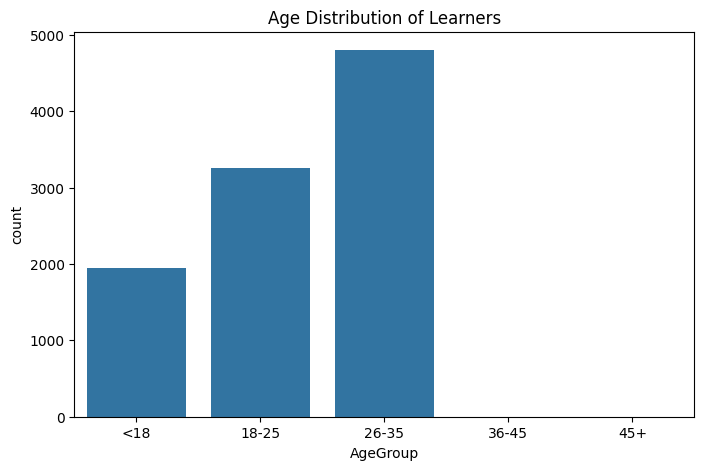

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="AgeGroup"
)

plt.title("Age Distribution of Learners")
plt.show()

Gender Distribution

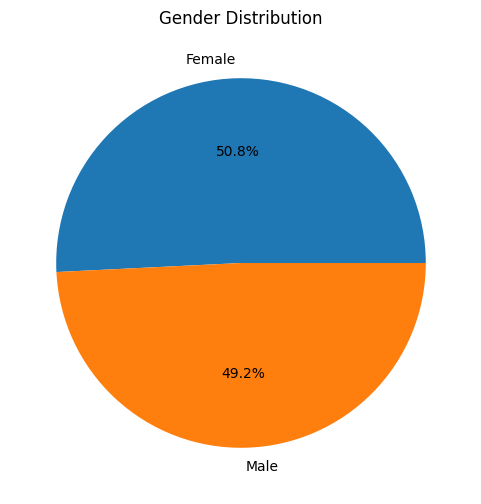

In [ ]:
gender = df["Gender"].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    gender,
    labels=gender.index,
    autopct="%1.1f%%"
)

plt.title("Gender Distribution")
plt.show()

Course Category Popularity

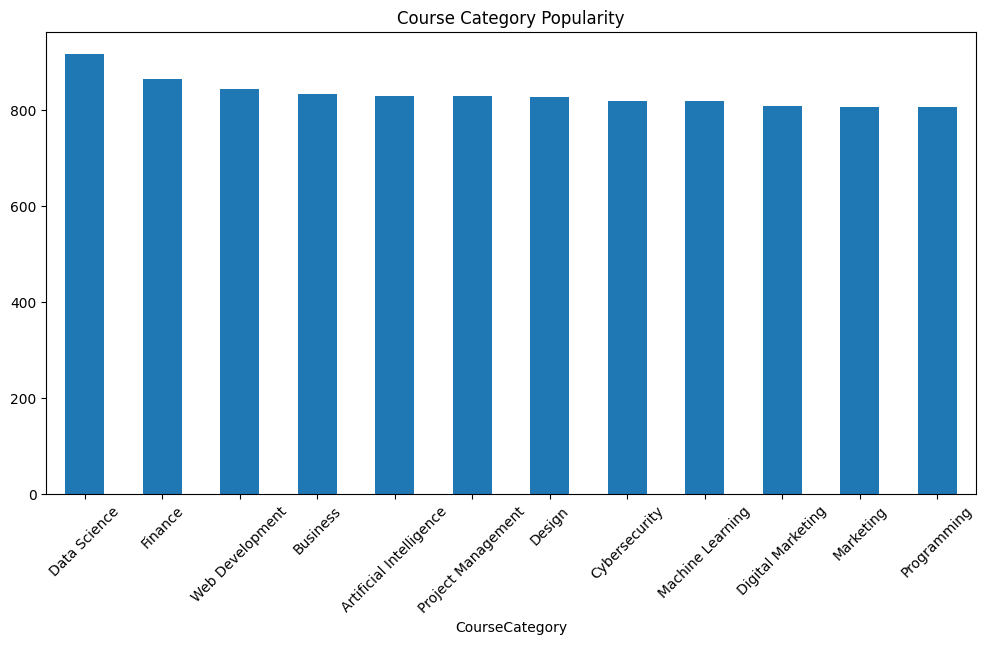

In [ ]:
plt.figure(figsize=(12,6))

df["CourseCategory"].value_counts().plot(
    kind="bar"
)

plt.title("Course Category Popularity")

plt.xticks(rotation=45)

plt.show()

Course Type Analysis

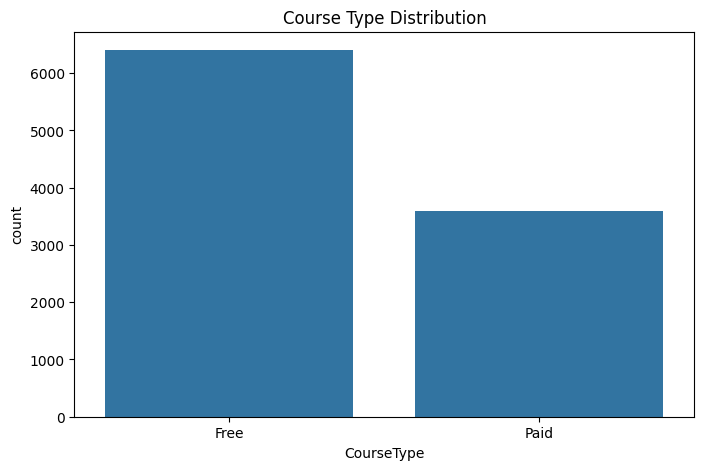

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="CourseType"
)

plt.title("Course Type Distribution")

plt.show()

Course Level Analysis

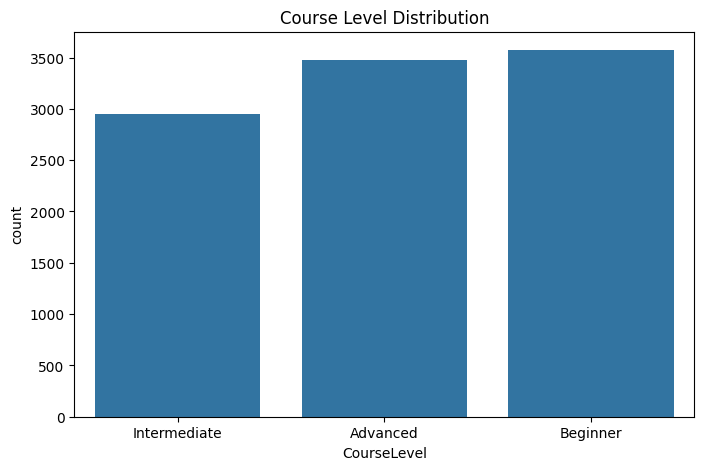

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="CourseLevel"
)

plt.title("Course Level Distribution")

plt.show()

Age Group vs Course Level

CourseLevel  Advanced  Beginner  Intermediate
AgeGroup                                     
<18               694       673           579
18-25            1140      1173           942
26-35            1641      1727          1431


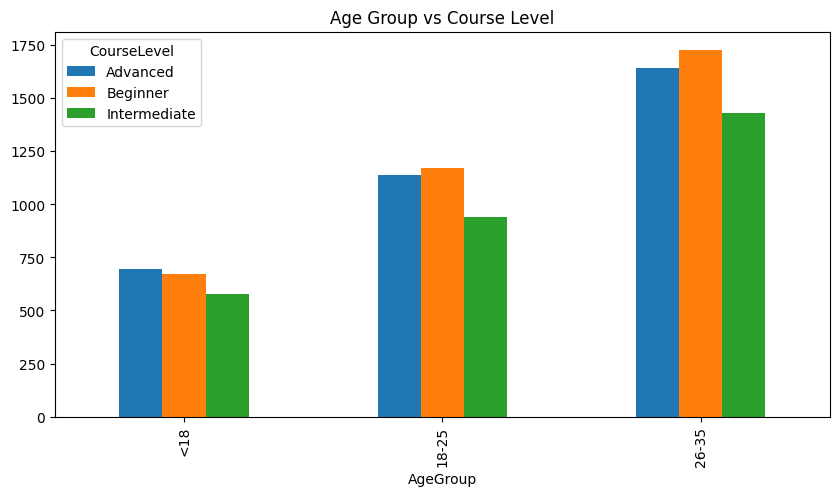

In [ ]:
cross = pd.crosstab(
    df["AgeGroup"],
    df["CourseLevel"]
)

print(cross)
cross.plot(
    kind="bar",
    figsize=(10,5)
)
plt.title(
    "Age Group vs Course Level"
)
plt.show()

Gender vs Course Level

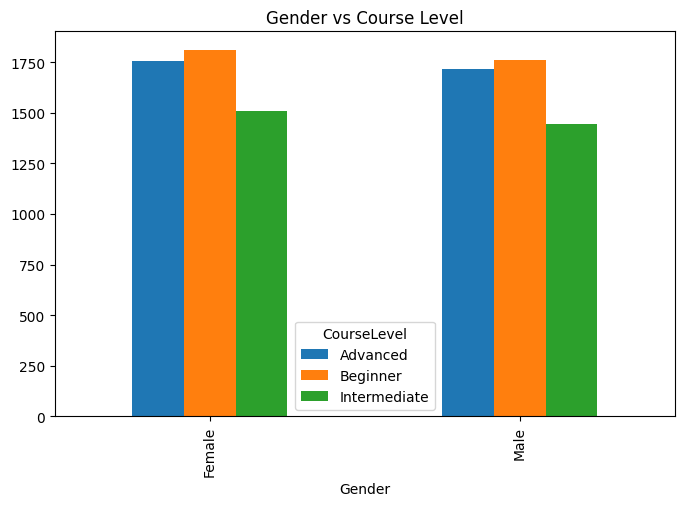

In [ ]:
cross = pd.crosstab(
    df["Gender"],
    df["CourseLevel"]
)

cross.plot(
    kind="bar"
)

plt.title(
    "Gender vs Course Level"
)

plt.show()

Age Group vs Course Category Heatmap

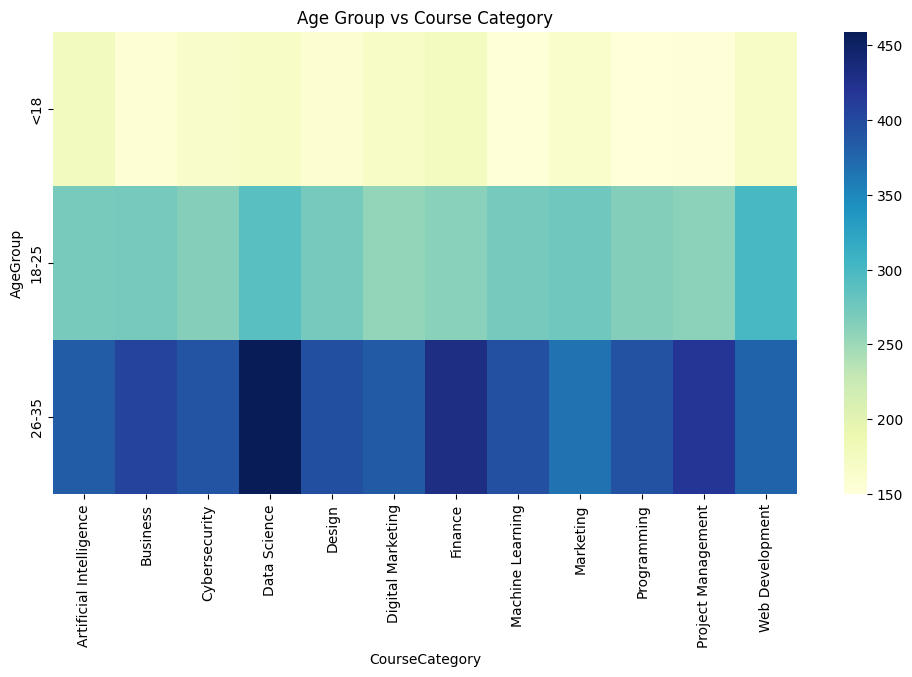

In [ ]:
table = pd.crosstab(
    df["AgeGroup"],
    df["CourseCategory"]
)
plt.figure(figsize=(12,6))

sns.heatmap(
    table,
    cmap="YlGnBu"
)
plt.title(
    "Age Group vs Course Category"
)
plt.show()

Average Courses per Learner

In [ ]:
avg = df.groupby(
    "UserID"
).size().mean()

print(
    "Average Courses Per Learner:",
    round(avg,2)
)

Average Courses Per Learner: 3.33


Most Active Learners

UserID
U00018    16
U00339    16
U00881    16
U00427    16
U00055    16
U00216    16
U01399    16
U01414    16
U01543    16
U01337    16
Name: count, dtype: int64


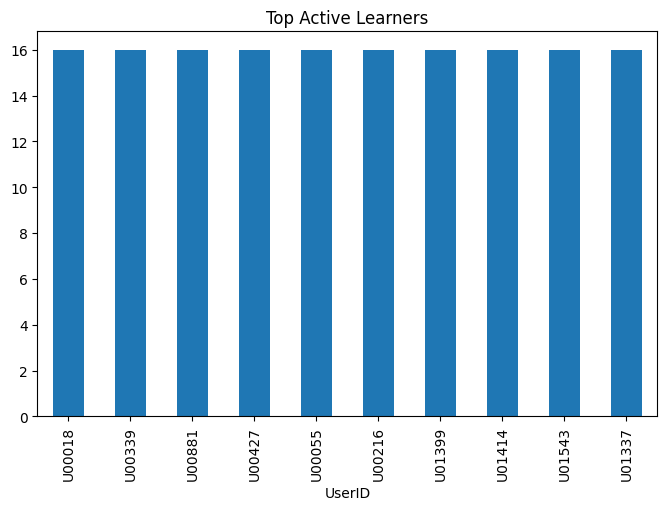

In [ ]:
top = df["UserID"].value_counts().head(10)
print(top)
top.plot(
    kind="bar"
)
plt.title(
    "Top Active Learners"
)
plt.show()